# 03 : Advanced models and tuning Step 3
We try models more powerful than the logistic regression of notebook 02, a random forest and
gradient boosting (LightGBM), and tune their hyperparameters.

Same protocol as notebook 02:
* only the train set (`dataset/train.csv`); the test set is only used in notebook 04;
* the same 5 stratified folds (`cv_folds()`) and the same score (PR-AUC);
* the preprocessing of `code/step2_preprocessing.py` is inside each pipeline, so it is fitted on the training
  folds only;
* we compare the train score and the CV score to see over/underfitting.

The tuned parameters are saved with `save_best_params()`. The two models are registered in `src/models.py`
(`random_forest`, `lightgbm`), so notebook 04 evaluates them on the test set and on the temporal split
automatically.

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path("..") / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RandomizedSearchCV, cross_validate, validation_curve
from scipy.stats import loguniform, randint, uniform

from common import *
from evaluation import SCORING, cv_summary
from models import get_model, save_best_params, BUILDERS
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
set_seed()
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(parents=True, exist_ok=True)

train, test = random_split()
X_train, y_train = xy(train)
print("train:", X_train.shape, " share of yes: %.4f" % y_train.mean())
# check that we use the full train set (32,940 rows, 11.3 % of yes), like notebook 02
assert len(X_train) == 32940, "train.csv is not complete: run code/step2_split.py again"
cv = cv_folds()

train: (32940, 20)  share of yes: 0.1127


`train.csv` is sorted by time (`row_order`). `cv_folds()` uses `shuffle=True`, otherwise each fold would be one
period of time and the folds would not be comparable.

In [2]:
rows = []

def evaluate(name, model):
    # 5-fold CV: mean and std of the validation scores + score on the training folds
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    row = cv_summary(s, name)
    row["gap_train_cv"] = row["train_pr_auc_mean"] - row["cv_pr_auc_mean"]
    return row

## 1. Reference: the baseline of notebook 02 (logistic regression, C = 0.1)

In [3]:
rows.append(evaluate("logreg_baseline", get_model("logreg_baseline")))
pd.DataFrame(rows)

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
0,logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,1.8942,0.0073


## 2. Random forest
### 2.1 With the default settings

In [4]:
rows.append(evaluate("random_forest (default)", BUILDERS["random_forest"]()))
pd.DataFrame(rows)

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
0,logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,1.8942,0.0073
1,random_forest (default),0.4026,0.0042,0.7667,0.0050,0.9990,0.0001,5.8218,0.5964


With the default settings the trees grow until every leaf is pure, so the forest learns the training folds
almost by heart: train PR-AUC 0.999 against 0.403 in CV (gap 0.60). This is strong overfitting, and the default
random forest is even worse than the baseline (0.403 vs 0.448, a loss of 0.046, much bigger than the std between
folds, about 0.005). A random forest is not better "by default": the size of the trees must be limited.

### 2.2 Effect of the maximum depth
Before the random search, we look at one hyperparameter alone to understand under- and overfitting.

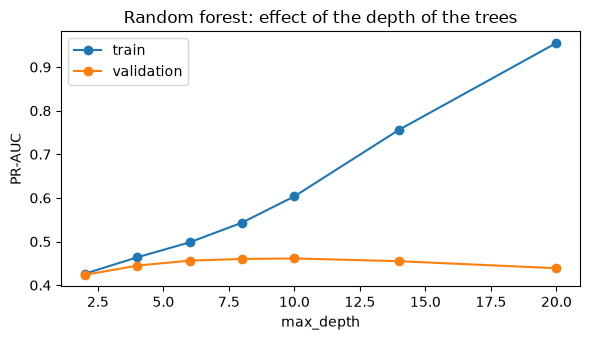

,max_depth,train,validation
0,2,0.4262,0.4235
1,4,0.4638,0.4449
2,6,0.4981,0.4562
3,8,0.5433,0.4600
4,10,0.6036,0.4612
5,14,0.7564,0.4549
6,20,0.9553,0.4388


In [5]:
depths = [2, 4, 6, 8, 10, 14, 20]
rf = BUILDERS["random_forest"]().set_params(model__n_estimators=150)
train_s, val_s = validation_curve(rf, X_train, y_train, param_name="model__max_depth", param_range=depths,
                                  cv=cv, scoring="average_precision", n_jobs=-1)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(depths, train_s.mean(axis=1), marker="o", label="train")
ax.plot(depths, val_s.mean(axis=1), marker="o", label="validation")
ax.set_xlabel("max_depth"); ax.set_ylabel("PR-AUC"); ax.legend()
ax.set_title("Random forest: effect of the depth of the trees")
plt.tight_layout(); plt.savefig(FIGURES / "rf_max_depth.png", dpi=150); plt.show()
pd.DataFrame({"max_depth": depths, "train": train_s.mean(axis=1), "validation": val_s.mean(axis=1)})

The curve shows the two sides of the bias/variance trade-off:
* **Depth 2 to 4: underfitting.** Train and validation are low and close (0.426 / 0.424 at depth 2): the trees are too
  simple, and the forest is even below the baseline.
* **Depth 8 to 10: best zone.** The validation score reaches its maximum (0.460 at depth 8, 0.461 at depth 10), but the
  gap already grows (0.08 then 0.14).
* **Depth 14 and more: overfitting.** The train score keeps going up (0.76 then 0.96) while the validation score goes
  down (0.455 then 0.439).

So the depth should stay around 8-10. The random search below confirms it: its best combination uses `max_depth = 10`.

### 2.3 Random search
10 random combinations (150 trees, depth limited to 20 to keep the search fast), same 5 folds.

In [6]:
rf_space = {
    "model__n_estimators": [150],
    "model__max_depth": [6, 8, 10, 14, 20],
    "model__min_samples_leaf": randint(1, 50),      # minimum number of rows in a leaf
    "model__max_features": ["sqrt", 0.3, 0.5],      # share of the variables tried at each split
    "model__class_weight": [None, "balanced_subsample"],
}
t0 = time.time()
rf_search = RandomizedSearchCV(BUILDERS["random_forest"](), rf_space, n_iter=10, cv=cv, scoring=SCORING,
                               refit="pr_auc", return_train_score=True, random_state=SEED, n_jobs=-1)
rf_search.fit(X_train, y_train)
rf_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in rf_search.best_params_.items()}
save_best_params("random_forest", rf_params)
print("search time: %.0f s" % (time.time() - t0))
print("best CV PR-AUC: %.4f" % rf_search.best_score_)
rf_params

search time: 128 s
best CV PR-AUC: 0.4653


{'model__class_weight': 'balanced_subsample',
 'model__max_depth': 10,
 'model__max_features': 0.5,
 'model__min_samples_leaf': 11,
 'model__n_estimators': 150}

In [7]:
# the 5 best combinations
cols = ["param_model__max_depth", "param_model__min_samples_leaf", "param_model__max_features",
        "param_model__class_weight", "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc"]
pd.DataFrame(rf_search.cv_results_).sort_values("mean_test_pr_auc", ascending=False)[cols].head(5)

,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,param_model__class_weight,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc
2,10,11,0.5,balanced_subsample,0.5717,0.4653,0.0038
0,14,15,sqrt,NaN,0.5439,0.4647,0.0060
3,20,22,0.5,NaN,0.5813,0.4633,0.0046
6,8,44,0.3,balanced_subsample,0.4973,0.4625,0.0051
8,14,47,0.5,balanced_subsample,0.5267,0.4623,0.0054


In [8]:
rows.append(evaluate("random_forest (tuned)", get_model("random_forest")))
pd.DataFrame(rows)

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
0,logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,1.8942,0.0073
1,random_forest (default),0.4026,0.0042,0.7667,0.0050,0.9990,0.0001,5.8218,0.5964
2,random_forest (tuned),0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,14.0013,0.1064


## 3. Gradient boosting (LightGBM)
Boosting builds many small trees one after the other: each new tree tries to correct the errors of the previous
ones. LightGBM is a fast library for this.

### 3.1 With the default settings

In [9]:
rows.append(evaluate("lightgbm (default)", BUILDERS["lightgbm"]()))
pd.DataFrame(rows)

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
0,logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,1.8942,0.0073
1,random_forest (default),0.4026,0.0042,0.7667,0.0050,0.9990,0.0001,5.8218,0.5964
2,random_forest (tuned),0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,14.0013,0.1064
3,lightgbm (default),0.4570,0.0072,0.7944,0.0059,0.6310,0.0012,1.5109,0.1740


### 3.2 Random search
Same idea: 10 random combinations, same 5 folds.

In [10]:
lgbm_space = {
    "model__n_estimators": randint(100, 600),        # number of trees
    "model__learning_rate": loguniform(0.01, 0.2),   # how much each tree corrects the previous ones
    "model__num_leaves": randint(8, 64),             # size of each tree
    "model__min_child_samples": randint(20, 300),    # minimum number of rows in a leaf
    "model__subsample": uniform(0.6, 0.4),           # share of the rows used by each tree
    "model__subsample_freq": [1],
    "model__colsample_bytree": uniform(0.5, 0.5),    # share of the columns used by each tree
    "model__reg_lambda": loguniform(0.01, 10),       # L2 regularisation
}
t0 = time.time()
lgbm_search = RandomizedSearchCV(BUILDERS["lightgbm"](), lgbm_space, n_iter=10, cv=cv, scoring=SCORING,
                                 refit="pr_auc", return_train_score=True, random_state=SEED, n_jobs=-1)
lgbm_search.fit(X_train, y_train)
lgbm_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in lgbm_search.best_params_.items()}
save_best_params("lightgbm", lgbm_params)
print("search time: %.0f s" % (time.time() - t0))
print("best CV PR-AUC: %.4f" % lgbm_search.best_score_)
lgbm_params

search time: 63 s
best CV PR-AUC: 0.4673


{'model__colsample_bytree': 0.831261142176991,
 'model__learning_rate': 0.02544166090938368,
 'model__min_child_samples': 73,
 'model__n_estimators': 205,
 'model__num_leaves': 11,
 'model__reg_lambda': 0.035856126103453984,
 'model__subsample': 0.9878338511058234,
 'model__subsample_freq': 1}

In [11]:
cols = ["param_model__n_estimators", "param_model__learning_rate", "param_model__num_leaves",
        "param_model__min_child_samples", "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc"]
pd.DataFrame(lgbm_search.cv_results_).sort_values("mean_test_pr_auc", ascending=False)[cols].head(5)

,param_model__n_estimators,param_model__learning_rate,param_model__num_leaves,param_model__min_child_samples,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc
7,205,0.0254,11,73,0.5037,0.4673,0.0089
5,415,0.0104,21,108,0.5106,0.4671,0.0080
3,269,0.0107,35,78,0.4996,0.4661,0.0068
4,343,0.0638,10,74,0.5454,0.4656,0.0075
6,530,0.0777,42,283,0.6693,0.4469,0.0059


In [12]:
rows.append(evaluate("lightgbm (tuned)", get_model("lightgbm")))
pd.DataFrame(rows)

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv
0,logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,1.8942,0.0073
1,random_forest (default),0.4026,0.0042,0.7667,0.0050,0.9990,0.0001,5.8218,0.5964
2,random_forest (tuned),0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,14.0013,0.1064
3,lightgbm (default),0.4570,0.0072,0.7944,0.0059,0.6310,0.0012,1.5109,0.1740
4,lightgbm (tuned),0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,1.7087,0.0364


## 4. Comparison (cross-validation)

In [13]:
cv_table = pd.DataFrame(rows).set_index("model")
cv_table["gain_vs_baseline"] = cv_table["cv_pr_auc_mean"] - cv_table.loc["logreg_baseline", "cv_pr_auc_mean"]
cv_table.to_csv(RESULTS / "cv_step3.csv")
cv_table

,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,train_pr_auc_mean,train_pr_auc_std,fit_time_s,gap_train_cv,gain_vs_baseline
model,,,,,,,,,
logreg_baseline,0.4484,0.0056,0.7886,0.0108,0.4558,0.0017,1.8942,0.0073,0.0000
random_forest (default),0.4026,0.0042,0.7667,0.0050,0.9990,0.0001,5.8218,0.5964,-0.0458
random_forest (tuned),0.4653,0.0038,0.7987,0.0065,0.5717,0.0021,14.0013,0.1064,0.0168
lightgbm (default),0.4570,0.0072,0.7944,0.0059,0.6310,0.0012,1.5109,0.1740,0.0086
lightgbm (tuned),0.4673,0.0089,0.8002,0.0063,0.5037,0.0018,1.7087,0.0364,0.0189


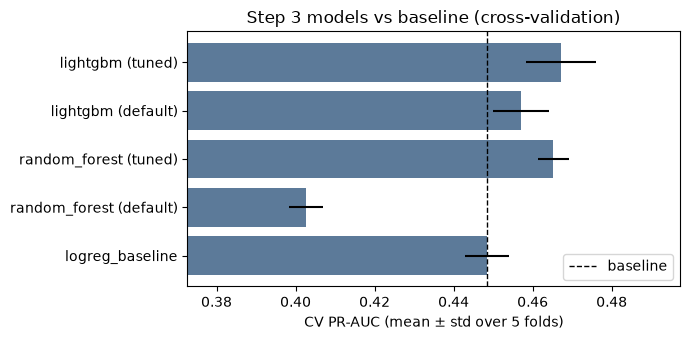

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cv_table.index, cv_table["cv_pr_auc_mean"], xerr=cv_table["cv_pr_auc_std"], color="#5c7a99")
ax.axvline(cv_table.loc["logreg_baseline", "cv_pr_auc_mean"], color="k", ls="--", lw=1, label="baseline")
lo = cv_table["cv_pr_auc_mean"].min() - 0.03
ax.set_xlim(lo, cv_table["cv_pr_auc_mean"].max() + 0.03)
ax.set_xlabel("CV PR-AUC (mean ± std over 5 folds)"); ax.legend(loc="lower right")
ax.set_title("Step 3 models vs baseline (cross-validation)")
plt.tight_layout(); plt.savefig(FIGURES / "cv_step3_comparison.png", dpi=150); plt.show()

## 5. What we learn
* **Both tuned models beat the baseline:** LightGBM 0.467 (+0.019) and random forest 0.465 (+0.017) against 0.448.
  These gains are about three times the std between folds (0.004 to 0.009), so they are not just noise. The ROC-AUC
  also goes up a little (0.789 → 0.799-0.800, close to the AUC ≈ 0.8 of Moro et al.).
* **We cannot separate the two tuned models:** 0.467 vs 0.465 is a difference of 0.002, smaller than the std. The
  4 best LightGBM combinations are all between 0.466 and 0.467: the score has reached a plateau and more random
  search would probably not help much.
* **The tuning was necessary**, mostly for the random forest: +0.063 (0.403 → 0.465) and a gap divided by 6
  (0.60 → 0.11). For LightGBM: +0.010 (0.457 → 0.467) and a gap divided by 5 (0.17 → 0.04).
* **Overfitting:** the tuned random forest still has a clear gap (train 0.57 vs CV 0.47), LightGBM much less
  (0.50 vs 0.47). LightGBM is also much faster (1.7 s per fit against 14 s). If we had to choose one, LightGBM
  generalises better for the same score.